In [76]:
import jax
jax.config.update('jax_enable_x64', True)
import jax.numpy as jnp
from jax import jit, value_and_grad, debug
import optax
import matplotlib.pyplot as plt

In [77]:
learning_rate = 0.03
gradient_descent_iterations = 1001

In [78]:
penalty_distance = 20
penalty_distance_relu = 15
distance_matrix = jnp.array([[penalty_distance, 2, 1, 1, 3],
                            [2, penalty_distance, 1, 3, 1],
                            [1, 1, penalty_distance, 2, 2],
                            [1, 3, 2, penalty_distance, 1],
                            [3, 1, 2, 1, penalty_distance]])


penalty_distance = 20
penalty_distance_relu = 20
distance_matrix = jnp.array([[penalty_distance, 2., 7., 1., 2.],
                            [2., penalty_distance, 2., 1., 1.],
                            [7., 2., penalty_distance, 2., 1.],
                            [1., 1., 2., penalty_distance, 2.],
                            [2., 1., 1., 2., penalty_distance]])



penalty_distance = 200
penalty_distance_relu = 300
distance_matrix =  jnp.array([[penalty_distance,  29,  82,  46,  68,  52,  72,  42,  51,  55],
                            [ 29,   penalty_distance,  55,  46,  42,  43,  43,  23,  23,  31],
                            [ 82,  55,   penalty_distance,  68,  46,  55,  23,  43,  41,  29],
                            [ 46,  46,  68,   penalty_distance,  82,  15,  72,  31,  62,  42],
                            [ 68,  42,  46,  82,   penalty_distance,  74,  23,  52,  21,  46],
                            [ 52,  43,  55,  15,  74,   penalty_distance,  61,  23,  55,  31],
                            [ 72,  43,  23,  72,  23,  61,   penalty_distance,  42,  23,  31],
                            [ 42,  23,  43,  31,  52,  23,  42,   penalty_distance,  33,  15],
                            [ 51,  23,  41,  62,  21,  55,  23,  33,   penalty_distance,  29],
                            [ 55,  31,  29,  42,  46,  31,  31,  15,  29,   penalty_distance]])



penalty_distance = 200
penalty_distance_relu = 300
distance_matrix = jnp.array([[ penalty_distance, 112,  49,  53,  13,  80,  12,  40,  78,  71,  72,  12,  15,  70,  56],
                            [112, penalty_distance,  71,  81, 122,  83, 106,  82,  91,  67,  40, 117,  97,  89,  90],
                            [ 49,  71, penalty_distance,  16,  62,  81,  39,  46,  42,  24,  34,  50,  36,  76,  66],
                            [ 53,  81,  16, penalty_distance,  66,  96,  41,  60,  28,  20,  47,  51,  44,  91,  80],
                            [ 13, 122,  62,  66, penalty_distance,  81,  25,  45,  91,  84,  83,  20,  26,  70,  56],
                            [ 80,  83,  81,  96,  81, penalty_distance,  85,  41, 122, 101,  64,  91,  71,  12,  25],
                            [ 12, 106,  39,  41,  25,  85, penalty_distance,  43,  65,  60,  66,  11,  14,  75,  61],
                            [ 40,  82,  46,  60,  45,  41,  43, penalty_distance,  87,  69,  47,  51,  29,  33,  21],
                            [ 78,  91,  42,  28,  91, 122,  65,  87, penalty_distance,  25,  66,  73,  71, 118, 108],
                            [ 71,  67,  24,  20,  84, 101,  60,  69,  25,  penalty_distance,  41,  70,  60,  98,  89],
                            [ 72,  40,  34,  47,  83,  64,  66,  47,  66,  41,   penalty_distance,  78,  57,  65,  60],
                            [ 12, 117,  50,  51,  20,  91,  11,  51,  73,  70,  78,   penalty_distance,  23,  81,  67],
                            [ 15,  97,  36,  44,  26,  71,  14,  29,  71,  60,  57,  23,   penalty_distance,  61,  48],
                            [ 70,  89,  76,  91,  70,  12,  75,  33, 118,  98,  65,  81,  61,   penalty_distance,  14],
                            [ 56,  90,  66,  80,  56,  25,  61,  21, 108,  89,  60,  67,  48,  14,   penalty_distance]])



# Adjecency matrix
adjacency_matrix = 9.9 * jnp.ones(distance_matrix.shape)  # - jnp.diag(jnp.full(distance_matrix.shape[0],9.9))

In [79]:
# Forbid way to starting city
distance_matrix_no_penalities = jnp.copy(distance_matrix)
# Distances for reverse way
distance_matrix_reverse_start = jnp.copy(distance_matrix)

In [80]:
# Reverse relu as penalty function
def reverse_relu(x, position, factor):
    return -factor*jnp.minimum(0.0, (x-position))

def get_distance_and_next_city(adjacency_matrix_row, distance_matrix_row):
    next_city = jnp.argmax(adjacency_matrix_row)
    return jnp.dot((adjacency_matrix_row/10), distance_matrix_row), next_city

def walk_complete_distance(adjacency_matrix, distance_matrix, distance_matrix_reverse_start):
    # Initialize distance and starting city
    distance = 0.0
    start_pos = 0
    # Start at starting city 0
    next_distance, next_city = get_distance_and_next_city(adjacency_matrix[start_pos], distance_matrix[start_pos])
    distance += next_distance
    # Penalize the visited city 
    distance_matrix = distance_matrix.at[:, start_pos].set(penalty_distance * jnp.ones(distance_matrix.shape[0]))
    # Go through all cities
    for i in range(adjacency_matrix.shape[0]-2):
        old_city = next_city
        next_distance, next_city = get_distance_and_next_city(adjacency_matrix[next_city], distance_matrix[next_city])
        distance += next_distance
        # Penalize the visited city
        distance_matrix = distance_matrix.at[:, old_city].set(penalty_distance * jnp.ones(distance_matrix.shape[0]))
    # Now allow the way back to starting city
    distance_matrix = distance_matrix.at[:, start_pos].set(distance_matrix_no_penalities[:, start_pos])
    next_distance, next_city = get_distance_and_next_city(adjacency_matrix[next_city], distance_matrix[next_city])
    distance += next_distance

    """
    # The revese way has to be the same as the forward way
    start_pos_rev = 0
    # Start at starting city 0
    next_distance, next_city = get_distance_and_next_city(adjacency_matrix[:, start_pos_rev], distance_matrix_reverse_start[:, start_pos_rev])
    distance += next_distance
    # Penalize the visited city
    distance_matrix_reverse_start = distance_matrix_reverse_start.at[start_pos_rev].set(penalty_distance * jnp.ones(distance_matrix.shape[0]))
    for i in range(adjacency_matrix.shape[0]-2):
        old_city = next_city
        next_distance, next_city = get_distance_and_next_city(adjacency_matrix[:, next_city], distance_matrix_reverse_start[:, next_city])
        distance += next_distance
        # Penalize the visited city
        distance_matrix_reverse_start = distance_matrix_reverse_start.at[old_city].set(penalty_distance * jnp.ones(distance_matrix.shape[0]))
    # Now allow the way back to starting city
    distance_matrix_reverse_start = distance_matrix_reverse_start.at[start_pos_rev].set(distance_matrix_no_penalities[start_pos_rev])
    next_distance, next_city = get_distance_and_next_city(adjacency_matrix[:, next_city], distance_matrix_reverse_start[:, next_city])
    distance += next_distance
    """
    
    return distance


In [81]:
@jit
def objective_function(adjacency_matrix, distance_matrix, distance_matrix_reverse_start):
    
    distance = walk_complete_distance(adjacency_matrix, distance_matrix, distance_matrix_reverse_start)

    for i in range(adjacency_matrix.shape[0]):
        # Get max and min probabilities of each row
        min_propability = jnp.min(adjacency_matrix[i])
        max_propability = jnp.max(adjacency_matrix[i])

        # Penalize if minimum is closer 
        distance += (penalty_distance_relu*2) * reverse_relu(min_propability, 0.0, 1)
        distance += (penalty_distance_relu*2) * reverse_relu(max_propability, 9.99, 0.05)

    return distance

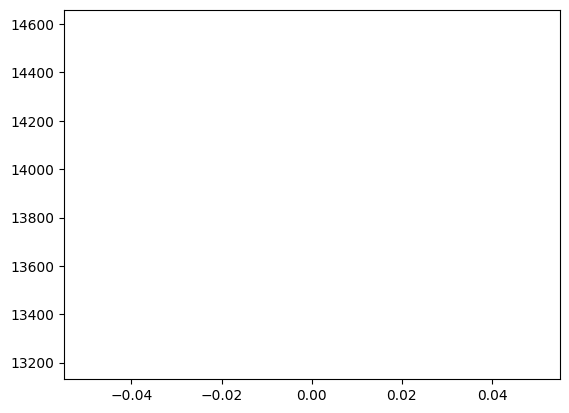

Distance:  13895.550000000017


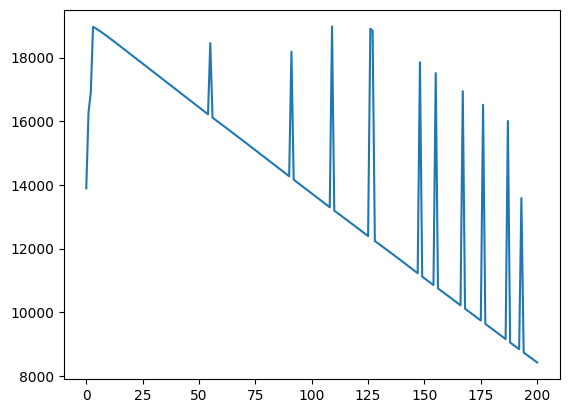

Distance:  8425.210835026639


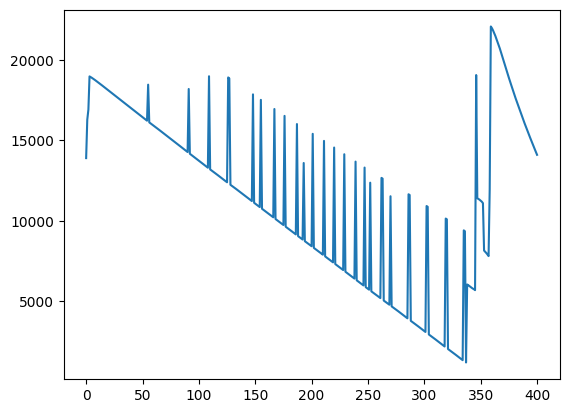

Distance:  14100.379363313563


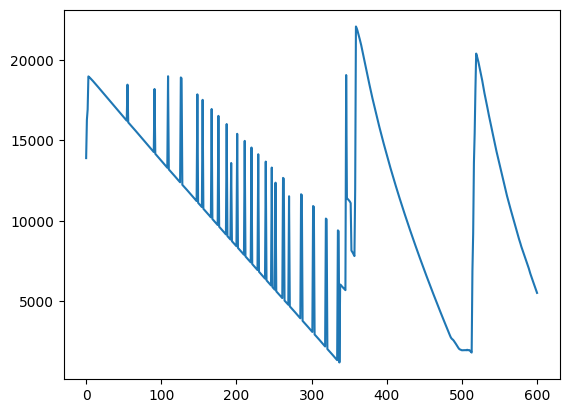

Distance:  5527.665119929687


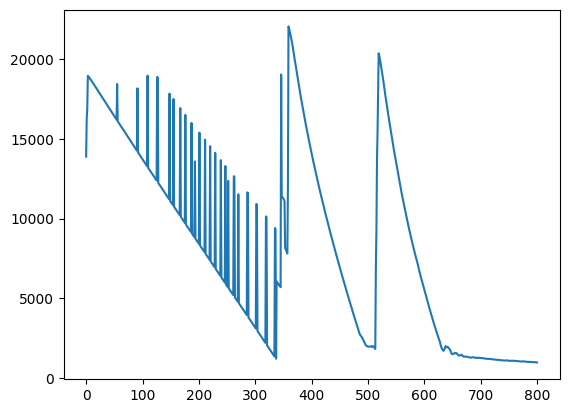

Distance:  971.120946878444


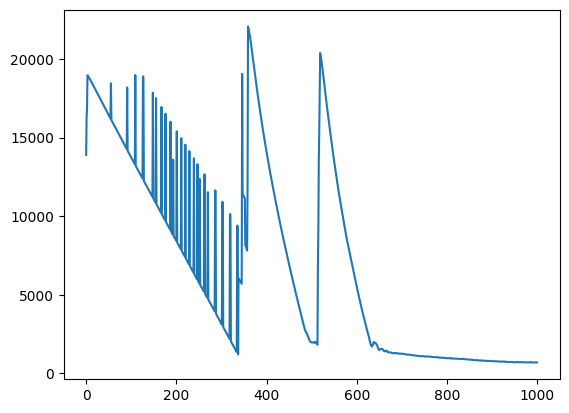

Distance:  700.0516743016708


In [82]:
optimizer = optax.adam(learning_rate=learning_rate) # optax.scale_by_lbfgs(memory_size=5)
opt_state = optimizer.init(adjacency_matrix)

distance_list = []

for i in range(gradient_descent_iterations):
    # distance = objective_function(adjacency_matrix, distance_matrix)
    
    distance, obj_grad = value_and_grad(objective_function)(adjacency_matrix, distance_matrix, distance_matrix_reverse_start)
    distance_list.append(distance)
    updates, opt_state = optimizer.update(obj_grad, opt_state, adjacency_matrix)
    adjacency_matrix = optax.apply_updates(adjacency_matrix, updates)
    # adjacency_matrix = adjacency_matrix - learning_rate * obj_grad

    if i%200 == 0:
        plt.plot(distance_list)
        plt.show()
        print("Distance: ", distance_list[-1])
    

In [83]:
print(adjacency_matrix/10)

[[ 7.22563958e-03  1.33965278e-02  4.52968595e-03  2.43182965e-02
   6.19637149e-02  7.83846831e-03  2.85839778e-01  3.14575453e-02
   1.29725835e-02  1.37170946e-02  1.49909353e-02  1.00051897e+00
   2.42185207e-02  1.68824139e-03  5.81814143e-03]
 [ 3.77105435e-04  3.77105435e-04  3.77105435e-04  3.77105435e-04
   3.77105435e-04  8.05732369e-03  3.77105435e-04  9.99128579e-01
   4.95725381e-03  3.77105435e-04  3.77105435e-04  3.77105435e-04
   3.77105435e-04  3.97584723e-03  4.42864449e-03]
 [ 4.90096947e-03  6.13460485e-03  2.03742548e-03  2.15501524e-03
   1.23678822e-03  8.98842232e-03  4.61699416e-03  2.03199203e-02
   2.37373930e-02  4.58151758e-03  1.01503758e+00  2.03742548e-03
   4.20302918e-03  1.60334128e-02  1.48533244e-02]
 [ 5.54578303e-03  8.37143477e-03  1.01209269e+00  9.41375871e-04
   3.91866399e-03  5.87000063e-03  5.38638261e-03  1.80965166e-02
   3.12759356e-02  4.74697328e-03  2.36126647e-02  9.41375871e-04
   5.53751504e-03  9.56209654e-03  1.27275922e-02]
 [ 7

In [84]:
print(jnp.round(adjacency_matrix/10))

distance_end = walk_complete_distance(jnp.round(adjacency_matrix/10)*10, distance_matrix, distance_matrix_reverse_start) #/ 2
print("Distance: ",distance_end)

[[ 0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  1.  0.  0.  0.]
 [ 0.  0.  0.  0.  0.  0.  0.  1.  0.  0.  0.  0.  0.  0.  0.]
 [ 0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  1.  0.  0.  0.  0.]
 [ 0.  0.  1.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.]
 [ 0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  1.  0.  0.]
 [ 0.  0.  0.  0.  0.  0.  0.  0.  1.  0.  0.  0.  0.  0.  0.]
 [ 0.  0.  0.  0.  0.  0.  0.  0.  0.  1.  0.  0.  0.  0.  0.]
 [ 0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  1.]
 [ 1.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.]
 [ 0.  0.  0.  1.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.]
 [-0.  1. -0. -0. -0.  0. -0.  0.  0. -0. -0. -0. -0.  0.  0.]
 [ 0.  0.  0.  0.  1.  0.  0.  0.  0.  0.  0. -0.  0.  0.  0.]
 [ 0.  0.  0.  0.  0.  0.  1.  0.  0.  0.  0.  0.  0.  0.  0.]
 [-0. -0. -0. -0. -0.  1. -0. -0.  0. -0. -0. -0. -0. -0. -0.]
 [ 0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  1.  0.]]
Distance:  571.0


In [85]:
# 10 x 10 Matrix:
# 0 → 1 → 8 → 4 → 6 → 2 → 9 → 7 → 5 → 3 → 0
# 247

In [86]:
# 15 x 15 Matrix:
# 0 → 12 → 7 → 14 → 13 → 5 → 1 → 10 → 9 → 8 → 3 → 2 → 6 → 11 → 4 → 0
# 407